In [9]:
import importlib
import const_learning_utils
importlib.reload(const_learning_utils)
from const_learning_utils import EndToEndSystem_bitwise, _inner_loop, run_experiment
import numpy as np
import tensorflow as tf
import sionna as sn
import gc
import os
import matplotlib.pyplot as plt
import MI_functions
importlib.reload(MI_functions)
from MI_functions import estimate_cm_capacity_pair_pn, binary_switching_algorithm
import itertools

In [10]:
snr_list = [13]
papr_list =  [7.2]

thz_frequency = 220e9

m = 5
M = 2 ** m
N = M  # Number of classes (symbols)
bits_per_symbol = int(np.log2(N))
shaping_bit_id = 0
use_upsampling_filtering = True  # Remove 'false' this after testing without upsampling and filtering
# APSK 32 points

symbol_points_apsk = [0.192425859850790 + 0.192425859850790j,
0.693946738059284 + 0.185942468053197j,
0.192425859850790 - 0.192425859850790j,
0.693946738059283 - 0.185942468053197j,
-0.192425859850790 + 0.192425859850790j,
-0.693946738059284 + 0.185942468053197j,
-0.192425859850790 - 0.192425859850790j,
-0.693946738059284 - 0.185942468053197j,
0.185942468053197 + 0.693946738059283j,
0.508004270006087 + 0.508004270006087j,
0.185942468053197 - 0.693946738059284j,
0.508004270006087 - 0.508004270006087j,
-0.185942468053197 + 0.693946738059284j,
-0.508004270006087 + 0.508004270006087j,
-0.185942468053197 - 0.693946738059283j,
-0.508004270006087 - 0.508004270006087j,
0.892855989707667 + 0.892855989707667j,
1.26268904989064 + 0.00000000000000j,
0.483210179621963 - 1.16657256912008j,
1.16657256912008 - 0.483210179621963j,
-0.483210179621963 + 1.16657256912008j,
-1.16657256912008 + 0.483210179621963j,
-0.892855989707668 - 0.892855989707667j,
-1.26268904989064 + 1.54634810326698e-16j,
0.483210179621963 + 1.16657256912008j,
1.16657256912008 + 0.483210179621963j,
-2.31952215490047e-16 - 1.26268904989064j,
0.892855989707667 - 0.892855989707668j,
7.73174051633490e-17 + 1.26268904989064j,
-0.892855989707667 + 0.892855989707667j,
-0.483210179621963 - 1.16657256912008j,
-1.16657256912008 - 0.483210179621962j]

constellation = np.array(symbol_points_apsk)
constellation = normalized_points

tau = 10
# snr_db = 15


# Batch size
batch_size = 10
papr_batch_size = 30
block_size = 4096-32*4

# No = tf.convert_to_tensor(1/(10**(snr_db/10)),tf.float32)
ebno_db = tf.random.uniform(shape=[batch_size], minval=58.0, maxval=59.0)
No_ = sn.phy.utils.ebnodb2no(ebno_db, num_bits_per_symbol=bits_per_symbol, coderate=1)
No_ = tf.expand_dims(No_, axis=-1)

symbolwise_demapping = False
neural_bitwise_demapping = True
model = EndToEndSystem_bitwise(N, constellation, papr_batch_size,
                                batch_size, block_size,
                               bits_per_symbol, shaping_bit_id,
                               use_upsampling_filtering, thz_frequency, symbolwise_demapping, neural_bitwise_demapping, tau) #normalized_points
_,_,_,_,_,y_out = model(No_)
initial_weights = model.get_weights()

demodulator_weights = np.load("demodulator_weights.npz")



In [11]:
y_out.shape

TensorShape([10, 3968])

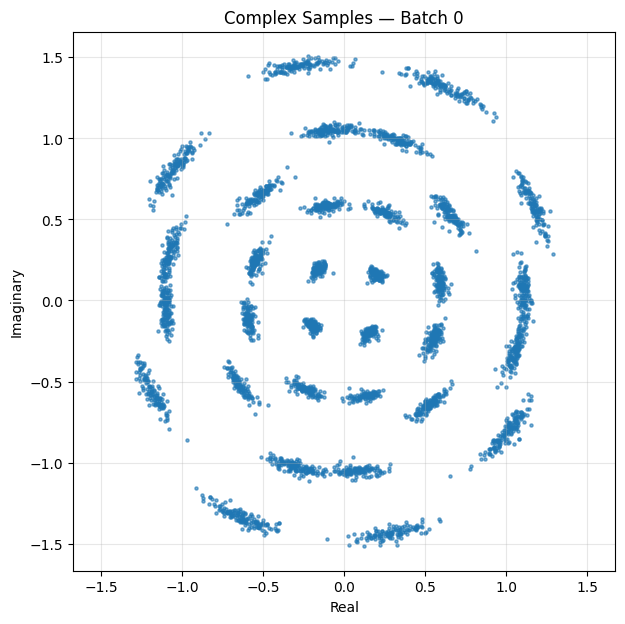

In [12]:
x_np = y_out.numpy()

batch = x_np[0]

plt.figure(figsize=(7, 7))
plt.scatter(
    batch.real,
    batch.imag,
    s=5,
    alpha=0.6
)

plt.xlabel("Real")
plt.ylabel("Imaginary")
plt.title("Complex Samples — Batch 0")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.show()

In [4]:

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# RESULTS_DIR = "results_32point_pn_220GHz"
# os.makedirs(RESULTS_DIR, exist_ok=True)
use_papr_constraint = False
outer_iterations = 2000
inner_initial_iterations = 5000
inner_iterations = 35
entropy_target = 4.66
ebno_db_minval = 4.0
ebno_db_maxval = 12.0

for snr_db in snr_list:
    for papr_db in papr_list:
        print('-------------------------------------------------------')
        print('PAPR :',papr_db,' dB')
        print('-------------------------------------------------------')
        model.set_weights(initial_weights)
        model.demodulator.set_weights([
            demodulator_weights["weight_0"],
            demodulator_weights["weight_1"],
            demodulator_weights["weight_2"],
            demodulator_weights["weight_3"],
            demodulator_weights["weight_4"],
            demodulator_weights["weight_5"]
        ])
        optimizer = tf.keras.optimizers.Adam(0.001)
        run_experiment(batch_size, bits_per_symbol,  model, optimizer, snr_db, papr_db, use_papr_constraint, entropy_target, outer_iterations, inner_initial_iterations, inner_iterations, ebno_db_minval, ebno_db_maxval)
        tf.keras.backend.clear_session()
        gc.collect()

# print("ALL EXPERIMENTS FINISHED")
print("Training constellation finished")

-------------------------------------------------------
PAPR : 7.2  dB
-------------------------------------------------------

===== Running SNR=13 dB | PAPR=7.2 dB =====

Iteration 0 L -0.132338747 loss -0.171817198 loss_ordinary 4.8247 entropy_value 4.99651718 glob_norm 40.0618973
Iteration 50 L -3.21143103 loss -3.21468306 loss_ordinary 1.54119587 entropy_value 4.75587893 glob_norm 15.4054518
Iteration 100 L -3.4240346 loss -3.42982554 loss_ordinary 1.35845077 entropy_value 4.7882762 glob_norm 43.4004555
Iteration 150 L -3.55968451 loss -3.56433487 loss_ordinary 1.210513 entropy_value 4.77484798 glob_norm 7.6850605
Iteration 200 L -3.52833748 loss -3.53316689 loss_ordinary 1.24388921 entropy_value 4.77705622 glob_norm 11.1850767
Iteration 250 L -3.56662631 loss -3.57326365 loss_ordinary 1.22413313 entropy_value 4.79739666 glob_norm 4.96912193
Iteration 300 L -3.62403703 loss -3.62980247 loss_ordinary 1.15818739 entropy_value 4.78799 glob_norm 7.93350649
Iteration 350 L -3.68962264 

In [5]:
def entropy(pdf, base=2):
    pdf = np.asarray(pdf, dtype=np.float64)
    pdf = pdf[pdf > 0]  # remove zero entries to avoid log(0)
    pdf /= np.sum(pdf)  # normalize to ensure valid probability distribution

    h = -np.sum(pdf * np.log(pdf) / np.log(base))
    return h


def normalize_constellation(points, probabilities):

    # Compute the power of the constellation
    power = np.sum(probabilities * np.abs(points)**2)
    # Normalize the constellation points
    normalized_points = points / np.sqrt(power)
    return normalized_points

def plot_constellation_wlabels_polar(points, probabilities, plot_title):
    points = np.asarray(points)
    probabilities = np.asarray(probabilities).flatten()

    # Convert to polar coordinates
    r = np.abs(points)
    theta = np.angle(points)  # in radians, [-π, π]

    # Scale marker sizes for visibility
    marker_sizes = 300 * probabilities / max(probabilities)

    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='polar')

    # Scatter in polar coordinates
    ax.scatter(theta, r, s=marker_sizes, alpha=0.7, c='b', edgecolors='k')

    # Annotate with 6-bit binary labels
    for i, (ri, ti) in enumerate(zip(r, theta)):
        label = format(i, '05b')  # 5-bit; use '06b' if you truly need 6 bits
        # Small offset in polar: add a bit to radius and angle
        ax.text(ti + 0.02, ri + 0.02, label, fontsize=9,
                ha='left', va='bottom', color='darkred')

    # Polar grid is automatic; tweak if desired
    ax.grid(True, linestyle=':')

    ax.set_title(plot_title, pad=20)

    plt.tight_layout()

# ------------------
# Save constellation
# ------------------
with tf.GradientTape() as tape:
    _, _, _, shaping_probs,_ = model(No_)

points = (
    model.modulator.constellation_real.numpy()
    + 1j * model.modulator.constellation_imag.numpy()
)
probs = shaping_probs.numpy()

entropy_finalized = entropy(probs)

normalized_points = normalize_constellation(points, probs)



Constellation saved


<Figure size 640x480 with 0 Axes>

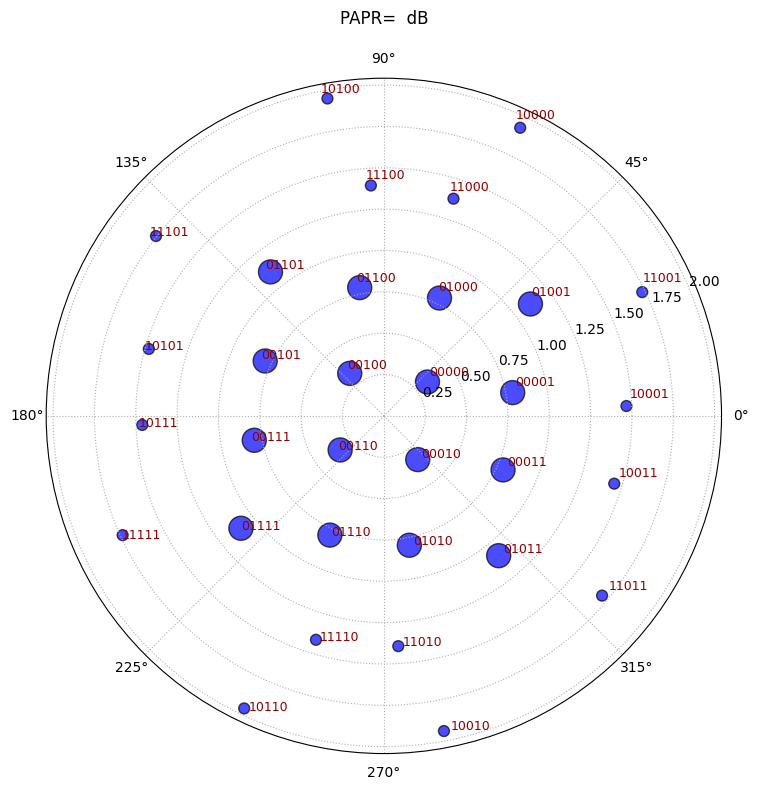

In [7]:
# exp_name = "32point_const"
# RESULTS_DIR = "results_32point_pn_220GHz"
# os.makedirs(RESULTS_DIR, exist_ok=True)
# np.save(f"{RESULTS_DIR}/{exp_name}_points.npy", normalized_points)
# np.save(f"{RESULTS_DIR}/{exp_name}_probs.npy", probs)

plt.figure()
plot_constellation_wlabels_polar(
    normalized_points,
    probs,
    "PAPR=  dB"
)
# plt.savefig(f"{RESULTS_DIR}/{exp_name}_constellation_entropy_{entropy_finalized}.png")
# plt.close()

print("Constellation saved")

In [98]:
for variable in model.trainable_variables:
    print(
        f"{variable.name}: "
        f"shape={variable.shape}, "
        f"dtype={variable.dtype}"
    )

kernel: shape=(1, 64), dtype=float32
bias: shape=(64,), dtype=float32
kernel: shape=(64, 64), dtype=float32
bias: shape=(64,), dtype=float32
kernel: shape=(64, 1), dtype=float32
bias: shape=(1,), dtype=float32
kernel: shape=(3, 128), dtype=float32
bias: shape=(128,), dtype=float32
kernel: shape=(128, 128), dtype=float32
bias: shape=(128,), dtype=float32
kernel: shape=(128, 5), dtype=float32
bias: shape=(5,), dtype=float32


In [99]:
# import numpy as np

demodulator_weights = model.demodulator.get_weights()

for i, weight in enumerate(demodulator_weights):
    print(
        f"weight[{i}]: "
        f"shape={weight.shape}, "
        f"dtype={weight.dtype}"
    )

np.savez(
    "demodulator_weights.npz",
    **{
        f"weight_{i}": weight
        for i, weight in enumerate(demodulator_weights)
    }
)

weight[0]: shape=(3, 128), dtype=float32
weight[1]: shape=(128,), dtype=float32
weight[2]: shape=(128, 128), dtype=float32
weight[3]: shape=(128,), dtype=float32
weight[4]: shape=(128, 5), dtype=float32
weight[5]: shape=(5,), dtype=float32


In [17]:

symbols_np = normalized_points
px = np.squeeze(probs)
px = px.astype(np.float64)

# Use GPU if available
print("GPUs:", tf.config.list_physical_devices('GPU'))

# =========================
# Parameters
# =========================
# EsNoVec = np.arange(-6, 35, 1, dtype=np.float32)   # Es/No in dB
EsNoVec = np.arange(-6, 35, 10, dtype=np.float32)   # Es/No in dB
N_bicm = 10_000_0

batch_size_mi = 500000  # tune based on GPU memory
EbNoVec = EsNoVec - 10 * np.log10(m)
symbols_np = symbols_np/np.sqrt(np.mean(np.abs(symbols_np)**2, axis=0, keepdims=True))

pn_var = 0.0032
#############

def normalize_symbols_for_px(symbols_np, px):
    avg_e = np.sum(px * (np.abs(symbols_np) ** 2))
    return symbols_np / np.sqrt(avg_e)

px /= px.sum()

symbols_np = normalize_symbols_for_px(symbols_np, px)
symbols = tf.constant(symbols_np, dtype=tf.complex64)

all_pairs = list(itertools.combinations(range(M), 2))

results_exact = {}

for idx_pair in all_pairs:
    idx_pair_tf = tf.constant(list(idx_pair), dtype=tf.int32)
    ccCap_pair, shannon = estimate_cm_capacity_pair_pn(
        px, EsNoVec, N_bicm, int(batch_size_mi/10), idx_pair_tf, symbols, pn_var,'awgn'
    )
    results_exact[idx_pair] = {
        "ccCap": ccCap_pair,
        "shannon": shannon
    }
    tf.print(f"Done pair {idx_pair}")


# Prepare arrays with unique names
save_dict = {}
for idx_pair, data in results_exact.items():
    i, j = idx_pair
    save_dict[f"ccCap_{i}_{j}"] = data["ccCap"]   # convert TF tensors to NumPy
    save_dict[f"shannon_{i}_{j}"] = data["shannon"]

# Save compressed
# np.savez_compressed(f"{RESULTS_DIR}/{exp_name}_results_exact_{entropy_finalized}.npz", **save_dict)
# print("Pairwise mutual information saved")

GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Es/No = -6.0 dB, Pair MI = 0.027913
Es/No = 4.0 dB, Pair MI = 0.227427
Es/No = 14.0 dB, Pair MI = 0.897863
Es/No = 24.0 dB, Pair MI = 1.000000
Es/No = 34.0 dB, Pair MI = 1.000000
Done pair (0, 1)
Es/No = -6.0 dB, Pair MI = 0.023473
Es/No = 4.0 dB, Pair MI = 0.207057
Es/No = 14.0 dB, Pair MI = 0.876719
Es/No = 24.0 dB, Pair MI = 1.000000
Es/No = 34.0 dB, Pair MI = 1.000000
Done pair (0, 2)
Es/No = -6.0 dB, Pair MI = 0.045992
Es/No = 4.0 dB, Pair MI = 0.357738
Es/No = 14.0 dB, Pair MI = 0.979701
Es/No = 24.0 dB, Pair MI = 1.000000
Es/No = 34.0 dB, Pair MI = 1.000000
Done pair (0, 3)
Es/No = -6.0 dB, Pair MI = 0.022047
Es/No = 4.0 dB, Pair MI = 0.188853
Es/No = 14.0 dB, Pair MI = 0.844368
Es/No = 24.0 dB, Pair MI = 1.000000
Es/No = 34.0 dB, Pair MI = 1.000000
Done pair (0, 4)
Es/No = -6.0 dB, Pair MI = 0.094643
Es/No = 4.0 dB, Pair MI = 0.612054
Es/No = 14.0 dB, Pair MI = 0.999763
Es/No = 24.0 dB, Pair MI = 1.000000


In [18]:
labels_improved, I_sum_current, I_sum_initial = binary_switching_algorithm(labels, px, results_exact, EsNoVec, np.array([0,2,3]), max_iter=100)

BSA initialized: M=32, initial cost=3.210588

=== Iteration 1 ===
Symbol costs (sorted): [(15, 0.32072168159676845), (11, 0.3200756413235526), (13, 0.3194365021419168), (9, 0.3185456950833544), (14, 0.3034855268460786)]
No improving swap found. BSA converged.

=== BSA Final Summary ===
Total iterations: 1
Initial cost: 3.210588
Final cost: 3.210588
Improvement: 0.000000 (0.00%)
Final labels: ['00000' '00001' '00010' '00011' '00100' '00101' '00110' '00111' '01000'
 '01001' '01010' '01011' '01100' '01101' '01110' '01111' '10000' '10001'
 '10010' '10011' '10100' '10101' '10110' '10111' '11000' '11001' '11010'
 '11011' '11100' '11101' '11110' '11111']


In [82]:
binary = np.array(labels_improved)
decimal = np.array([int(bits, 2) for bits in binary])
symbols_np_adjusted = symbols_np[np.argsort(decimal)]

Bit labeling optimization done


<Figure size 640x480 with 0 Axes>

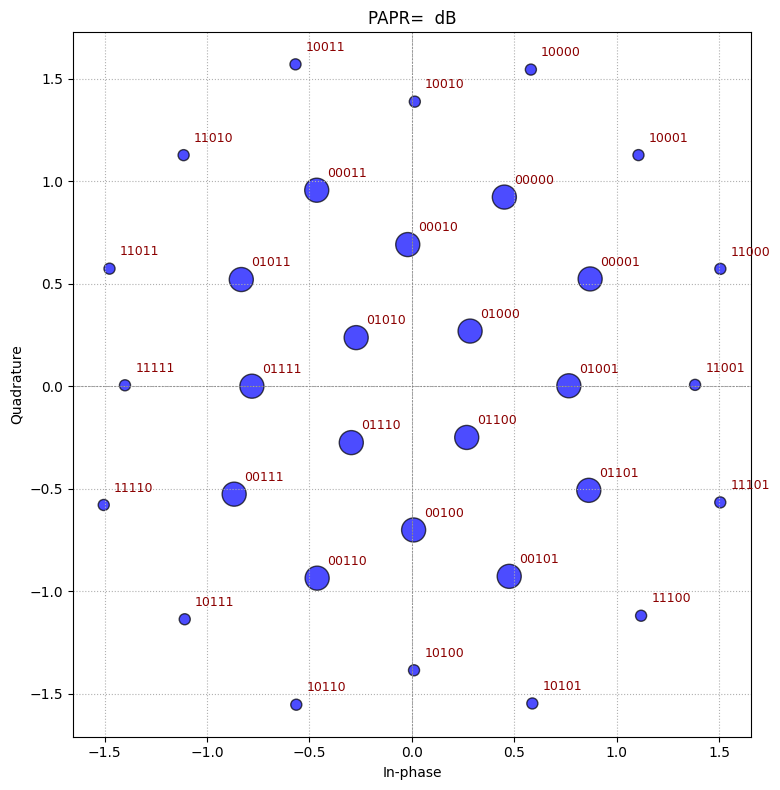

In [85]:
plt.figure()
plot_constellation_wlabels(
    symbols_np_adjusted,
    probs,
    "PAPR=  dB"
)
# plt.savefig(f"{RESULTS_DIR}/adjusted_{exp_name}_constellation_entropy_{entropy_finalized}.png")
# plt.close()
# np.save(f"{RESULTS_DIR}/adjusted_{exp_name}_points.npy", symbols_np_adjusted)
print("Bit labeling optimization done")

<Figure size 640x480 with 0 Axes>

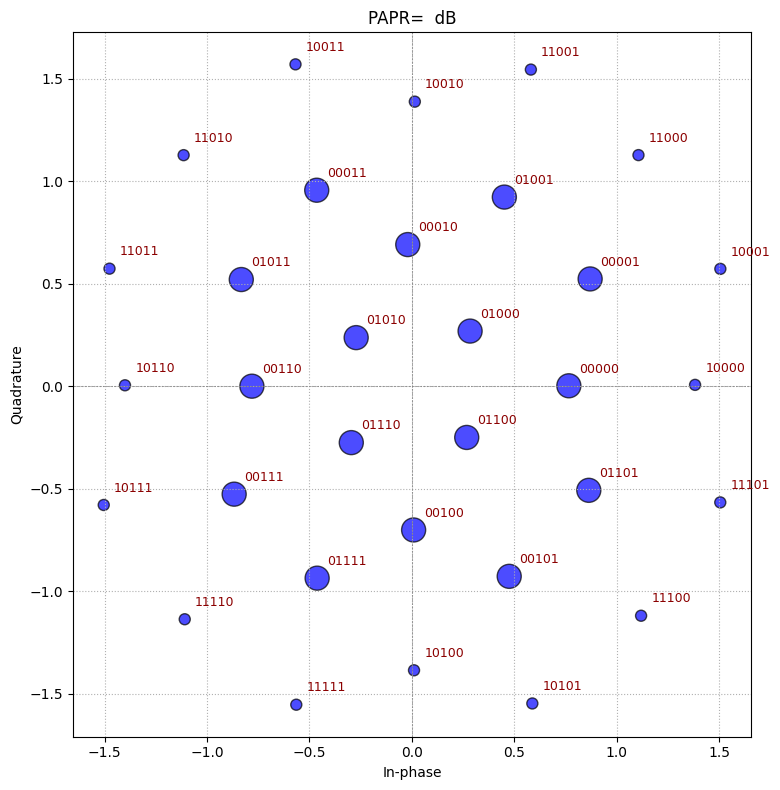

In [84]:
plt.figure()
plot_constellation_wlabels(
    symbols_np,
    probs,
    "PAPR=  dB"
)